# EDA charts

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
V1 = next(p for p in [ROOT / "data" / "version1", ROOT / "data" / "v1"] if p.exists())
V2 = next(p for p in [ROOT / "data" / "version2", ROOT / "data" / "v2"] if p.exists())
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

NAVY, TEAL, GRAY, INK, GRID = "#1D3B56", "#177F79", "#5F656B", "#1A1A1A", "#E9EEF3"
G = ["DeFi", "DEX", "Infrastructure", "NFT", "Gaming"]
Y = np.arange(len(G))[::-1]
W, H = 9, 4.6
VAL = dict(va="center", fontsize=16, fontweight="bold", color=INK)

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 17, "xtick.labelsize": 15, "ytick.labelsize": 17, "axes.labelsize": 16,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK, "xtick.color": GRAY, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 15,
})


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=200, facecolor="white", bbox_inches="tight", pad_inches=0.1)
    plt.show()


def legend_top(ax):
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)


def category_axis(ax):
    ax.set_yticks(Y, G)
    ax.set_ylabel("Category")
    ax.tick_params(axis="y", length=0)


def dumbbell(ax, a, b, label_a, label_b, fmt):
    for y, g in zip(Y, G):
        ax.plot([a[g], b[g]], [y, y], color=GRAY, linewidth=2, zorder=1)
        ax.scatter(a[g], y, s=120, color="white", edgecolor=NAVY, linewidth=2.5, zorder=2)
        ax.scatter(b[g], y, s=120, color=TEAL, zorder=3)
        ax.text(max(a[g], b[g]) * 1.35, y, fmt(a[g], b[g]), **VAL)
    ax.scatter([], [], s=100, color="white", edgecolor=NAVY, linewidth=2.5, label=label_a)
    ax.scatter([], [], s=100, color=TEAL, label=label_b)
    ax.set_xscale("log")
    category_axis(ax)
    legend_top(ax)


def paired_bars(ax, a, b, label_a, label_b, xlabel, xmax):
    ax.barh(Y + 0.18, [a[g] for g in G], height=0.34, color=NAVY, label=label_a)
    ax.barh(Y - 0.18, [b[g] for g in G], height=0.34, color=TEAL, label=label_b)
    for y, g in zip(Y, G):
        ax.text(a[g] + xmax * 0.012, y + 0.18, f"{a[g]:.0f}%", **VAL)
        ax.text(b[g] + xmax * 0.012, y - 0.18, f"{b[g]:.0f}%", **VAL)
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel)
    category_axis(ax)
    legend_top(ax)

In [2]:
panel = pd.read_csv(V1 / "dapp_panel.csv", parse_dates=["month"])
panel_2025 = panel[panel["month"].dt.year == 2025]

lifecycle = pd.read_csv(V2 / "dapp_lifecycle.csv")
category_month = pd.read_csv(V2 / "category_month.csv", parse_dates=["month"])
concentration = pd.read_csv(V2 / "concentration_month.csv")
retention = (pd.read_csv(V2 / "cohort_retention.csv")
               .merge(lifecycle[["slug", "category_group"]], left_on="protocol", right_on="slug", how="left"))

print(f"dataset 1: {panel['slug'].nunique()} apps, {panel['month'].min():%b %Y} to {panel['month'].max():%b %Y}")
print(f"dataset 2: {lifecycle['slug'].nunique()} apps, {category_month['month'].min():%b %Y} to {category_month['month'].max():%b %Y}, "
      f"{category_month['month'].nunique()} months")

dataset 1: 744 apps, Jan 2018 to Sep 2026
dataset 2: 622 apps, Jan 2025 to Dec 2025, 12 months


## Slide 4. Dataset 1

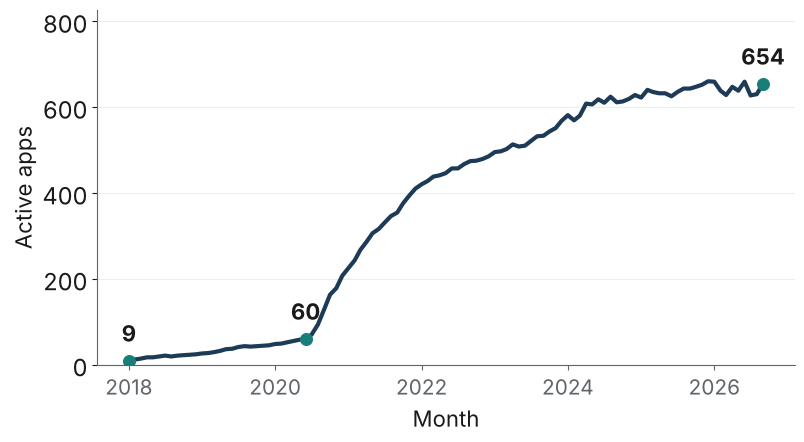

In [3]:
active_apps = panel[panel["active_wallets"] > 0].groupby("month")["slug"].nunique()

fig, ax = plt.subplots(figsize=(W, H))
ax.plot(active_apps.index, active_apps.values, color=NAVY, linewidth=3)
for d in [active_apps.index[0], pd.Timestamp("2020-06-01"), active_apps.index[-1]]:
    ax.scatter(d, active_apps[d], color=TEAL, s=70, zorder=3)
    ax.text(d, active_apps[d] + 45, f"{active_apps[d]}", ha="center", fontsize=16, fontweight="bold", color=INK)
ax.set_ylim(0, active_apps.max() * 1.25)
ax.grid(axis="y", color=GRID)
ax.set_xlabel("Month")
ax.set_ylabel("Active apps")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "fig2_active_apps_by_month.png")

In [4]:
static = panel.drop_duplicates("slug")
missing_rows = (panel[["listed_date", "first_deployed", "wallet_growth_mom"]].isna().mean() * 100).round(0)
famous = ["uniswap-v2", "uniswap-v3", "aave-v2", "aave-v3", "opensea-seaport", "blur"]

print(f"apps: {static['slug'].nunique()}")
print(f"apps without a token: {(~static['has_token'].astype(bool)).sum()} of {len(static)}")
print("rows with a missing value (%):")
print(missing_rows)
print("in dataset 1:", {s: s in set(panel["slug"]) for s in famous})

apps: 744
apps without a token: 2 of 744
rows with a missing value (%):
listed_date          36.0
first_deployed        1.0
wallet_growth_mom    10.0
dtype: float64
in dataset 1: {'uniswap-v2': False, 'uniswap-v3': True, 'aave-v2': False, 'aave-v3': True, 'opensea-seaport': False, 'blur': False}


## Slide 5. Dataset 1 vs. 2, 2025

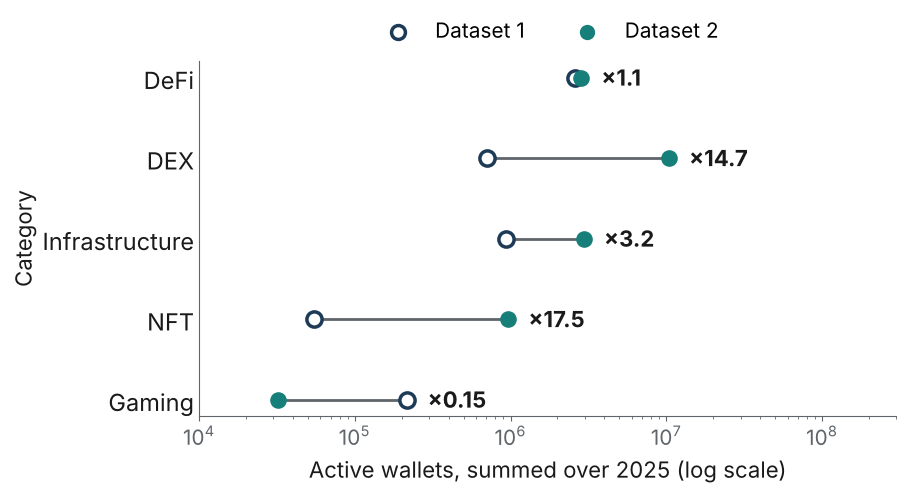

category_group
DeFi               1.09
DEX               14.74
Infrastructure     3.16
NFT               17.52
Gaming             0.15
Name: dataset 2 / dataset 1, dtype: float64

In [5]:
v1_wallets = panel_2025.groupby("category_group")["active_wallets"].sum()
v2_wallets = category_month.groupby("category_group")["active_wallets"].sum()

fig, ax = plt.subplots(figsize=(W, H))
dumbbell(ax, v1_wallets, v2_wallets, "Dataset 1", "Dataset 2",
         lambda a, b: f"×{b / a:.1f}" if b > a else f"×{b / a:.2f}")
ax.set_xlim(1e4, 3e8)
ax.set_xlabel("Active wallets, summed over 2025 (log scale)")
save(fig, "fig3_wallets_by_category_2025.png")

(v2_wallets / v1_wallets).loc[G].round(2).rename("dataset 2 / dataset 1")

In [6]:
v1_apps, v2_apps = set(panel["slug"]), set(lifecycle["slug"])
v1_apps_2025 = set(panel_2025.loc[panel_2025["active_wallets"] > 0, "slug"])
no_token = ~lifecycle["has_token"].astype(bool)

print(f"dataset 2 apps without a token: {no_token.sum()} of {len(lifecycle)} ({no_token.mean():.0%})")
print(f"apps in both datasets: {len(v1_apps & v2_apps)} (both active in 2025: {len(v1_apps_2025 & v2_apps)})")
print(f"only in dataset 2: {len(v2_apps - v1_apps)}, of which without a token: "
      f"{no_token[lifecycle['slug'].isin(v2_apps - v1_apps)].sum()}")
print(f"Gaming apps in both: {len(set(lifecycle.loc[lifecycle['category_group'] == 'Gaming', 'slug']) & v1_apps)}")

dataset 2 apps without a token: 229 of 622 (37%)
apps in both datasets: 247 (both active in 2025: 240)
only in dataset 2: 375, of which without a token: 227
Gaming apps in both: 1


## Slide 6. Inside DeFi

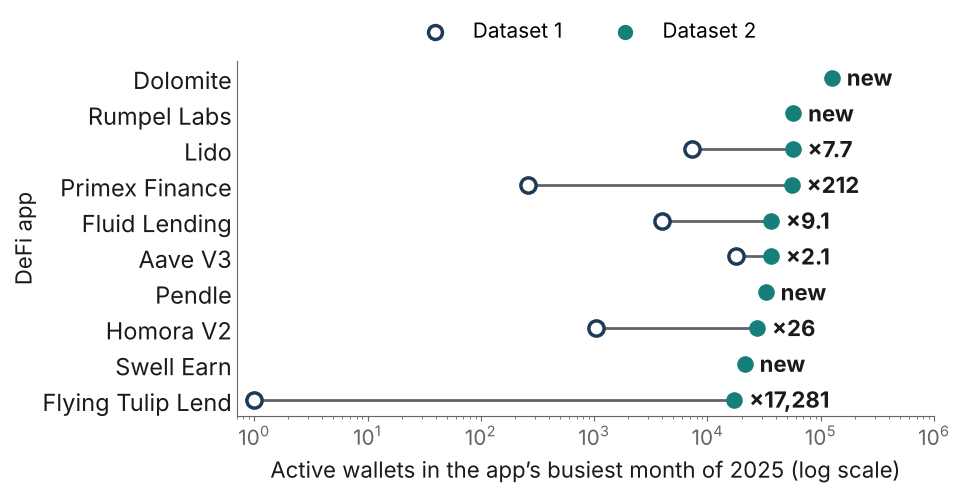

,slug,name,peak_wallets,v1_peak,ratio
167,dolomite,Dolomite,125561.0,NaN,NaN
454,rumpel-labs,Rumpel Labs,57248.0,NaN,NaN
301,lido,Lido,56584.0,7334.0,7.7
423,primex-finance,Primex Finance,55533.0,262.0,212.0
203,fluid-lending,Fluid Lending,36439.0,4007.0,9.1
9,aave-v3,Aave V3,36402.0,17711.0,2.1
402,pendle,Pendle,32726.0,NaN,NaN
253,homora-v2,Homora V2,27443.0,1045.0,26.3
524,swell-earn,Swell Earn,21363.0,NaN,NaN
204,flying-tulip-lend,Flying Tulip Lend,17281.0,1.0,17281.0


In [7]:
v1_peak = panel_2025.groupby("slug")["active_wallets"].max()
top = lifecycle[lifecycle["category_group"] == "DeFi"].nlargest(10, "peak_wallets")[["slug", "name", "peak_wallets"]]
top["v1_peak"] = top["slug"].map(v1_peak)
yy = np.arange(len(top))[::-1]

fig, ax = plt.subplots(figsize=(W, H))
for y, r in zip(yy, top.itertuples()):
    if pd.notna(r.v1_peak) and r.v1_peak > 0:
        ratio = r.peak_wallets / r.v1_peak
        ax.plot([r.v1_peak, r.peak_wallets], [y, y], color=GRAY, linewidth=2, zorder=1)
        ax.scatter(r.v1_peak, y, s=120, color="white", edgecolor=NAVY, linewidth=2.5, zorder=2)
        label = f"×{ratio:,.0f}" if ratio >= 10 else f"×{ratio:.1f}"
    else:
        label = "new"
    ax.scatter(r.peak_wallets, y, s=120, color=TEAL, zorder=3)
    ax.text(r.peak_wallets * 1.35, y, label, **VAL)
ax.scatter([], [], s=100, color="white", edgecolor=NAVY, linewidth=2.5, label="Dataset 1")
ax.scatter([], [], s=100, color=TEAL, label="Dataset 2")
ax.set_yticks(yy, top["name"])
ax.set_ylabel("DeFi app")
ax.tick_params(axis="y", length=0)
ax.set_xscale("log")
ax.set_xlim(0.7, 1e6)
ax.set_xlabel("Active wallets in the app’s busiest month of 2025 (log scale)")
legend_top(ax)
save(fig, "fig4_defi_top10_apps.png")

top.assign(ratio=(top["peak_wallets"] / top["v1_peak"]).round(1))

## Slide 7. Dataset 2 tables

In [8]:
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in
              {"category_month": category_month, "concentration_month": concentration,
               "dapp_lifecycle": lifecycle, "cohort_retention": pd.read_csv(V2 / "cohort_retention.csv")}.items()}).T

,rows,columns
category_month,84,9
concentration_month,288,10
dapp_lifecycle,622,29
cohort_retention,19939,6


## Slide 8. Dataset 2 size distribution

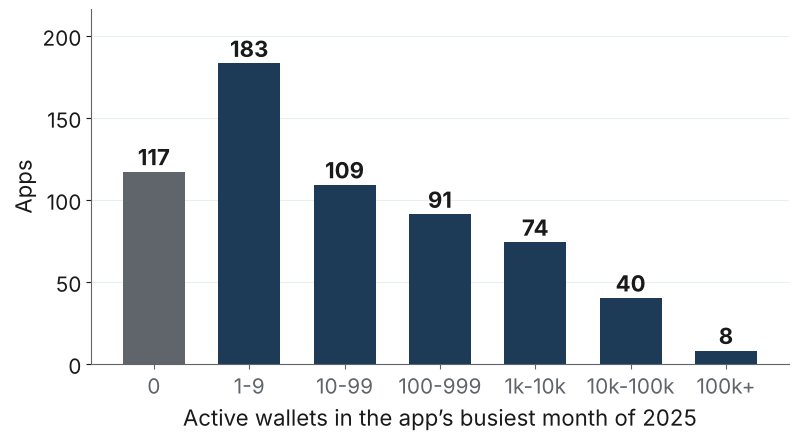

peak_wallets
0           117
1-9         183
10-99       109
100-999      91
1k-10k       74
10k-100k     40
100k+         8
Name: count, dtype: int64

In [9]:
bins = [-1, 0, 9, 99, 999, 9999, 99999, 1e12]
labels = ["0", "1-9", "10-99", "100-999", "1k-10k", "10k-100k", "100k+"]
counts = pd.cut(lifecycle["peak_wallets"], bins, labels=labels).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(W, H))
x = np.arange(len(labels))
ax.bar(x, counts.values, color=[GRAY] + [NAVY] * (len(labels) - 1), width=0.65)
for i, v in enumerate(counts.values):
    ax.text(i, v + 4, f"{v}", ha="center", fontsize=16, fontweight="bold", color=INK)
ax.set_xticks(x, labels)
ax.tick_params(axis="y", labelsize=15)
ax.set_ylim(0, counts.max() * 1.18)
ax.grid(axis="y", color=GRID)
ax.set_axisbelow(True)
ax.set_xlabel("Active wallets in the app’s busiest month of 2025")
ax.set_ylabel("Apps")
save(fig, "fig5_dataset2_peak_distribution.png")
counts

In [10]:
print(f"under 100 wallets at peak: {(lifecycle['peak_wallets'] < 100).mean():.0%}")
print(f"passed 10,000: {(lifecycle['peak_wallets'] >= 10000).sum()} apps")
print(f"cohort apps not in lifecycle: {retention['category_group'].isna().groupby(retention['protocol']).all().sum()}")

under 100 wallets at peak: 66%
passed 10,000: 48 apps
cohort apps not in lifecycle: 4


## Slide 10. Q1: Categories

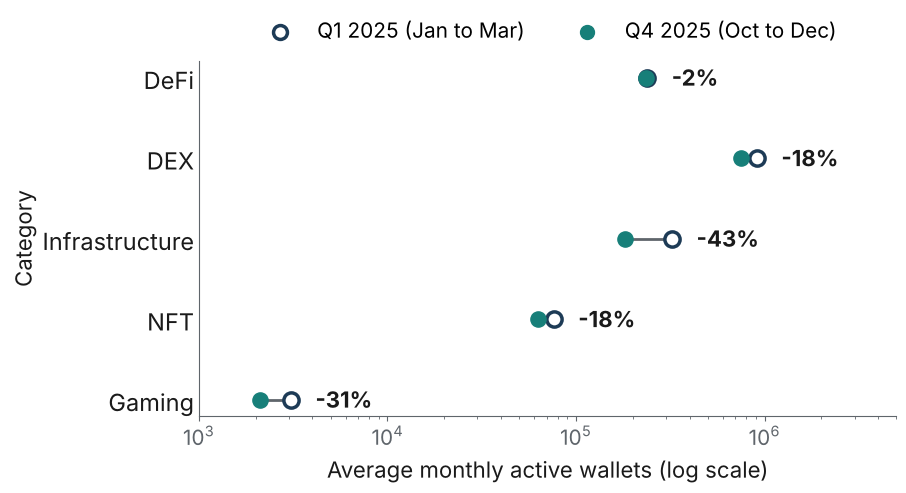

category_group
DeFi              -2.0
DEX              -18.0
Infrastructure   -43.0
NFT              -18.0
Gaming           -31.0
Name: Q1 to Q4 change (%), dtype: float64

In [11]:
by_quarter = (category_month.assign(q=category_month["month"].dt.quarter)
              .groupby(["category_group", "q"])["active_wallets"].mean().unstack())

fig, ax = plt.subplots(figsize=(W, H))
dumbbell(ax, by_quarter[1], by_quarter[4], "Q1 2025 (Jan to Mar)", "Q4 2025 (Oct to Dec)",
         lambda a, b: f"{(b / a - 1) * 100:+.0f}%")
ax.set_xlim(1e3, 5e6)
ax.set_xlabel("Average monthly active wallets (log scale)")
save(fig, "fig6_q1_quarter1_vs_quarter4.png")

((by_quarter[4] / by_quarter[1] - 1) * 100).loc[G].round(0).rename("Q1 to Q4 change (%)")

In [12]:
new_apps = category_month.groupby("category_group")["newly_launched"].sum().loc[G]
print(f"new apps in 2025, five groups: {new_apps.sum()}, of which DeFi: {new_apps['DeFi']}")
new_apps

new apps in 2025, five groups: 79, of which DeFi: 66


category_group
DeFi              66
DEX                8
Infrastructure     4
NFT                1
Gaming             0
Name: newly_launched, dtype: int64

## Slide 11. Q2: Concentration

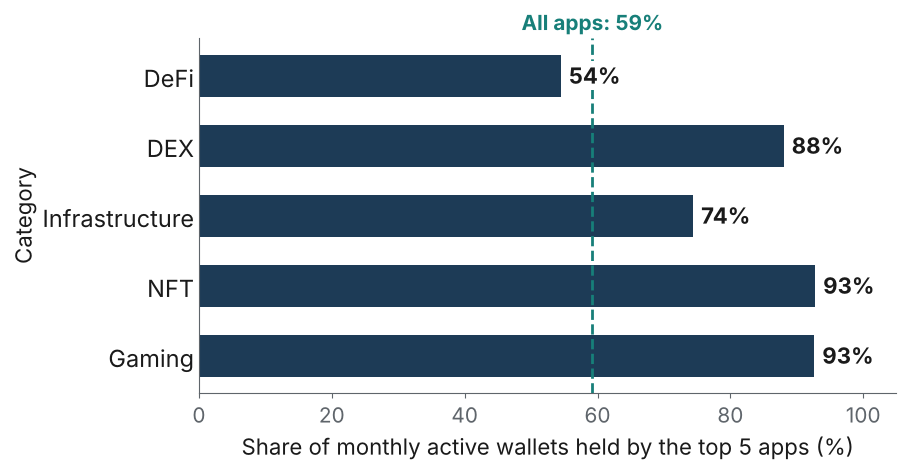

,n_dapps,top5_share,top10_share,gini
category_group,,,,
DeFi,209.00,0.54,0.74,0.92
DEX,40.50,0.88,0.97,0.88
Infrastructure,49.42,0.74,0.90,0.84
NFT,22.75,0.93,0.98,0.86
Gaming,9.92,0.93,1.00,0.56


In [13]:
wallets = concentration[concentration["metric"] == "active_wallets"]
by_cat = wallets[wallets["scope"] == "category"].groupby("category_group")[["n_dapps", "top5_share", "top10_share", "gini"]].mean()
whole = wallets[wallets["scope"] == "ecosystem"]
top5 = by_cat["top5_share"] * 100
all_top5 = whole["top5_share"].mean() * 100

fig, ax = plt.subplots(figsize=(W, H))
ax.barh(Y, [top5[g] for g in G], color=NAVY, height=0.6)
for y, g in zip(Y, G):
    ax.text(top5[g] + 1.2, y, f"{top5[g]:.0f}%", bbox=dict(fc="white", ec="none", pad=1), zorder=4, **VAL)
ax.axvline(all_top5, color=TEAL, linestyle="--", linewidth=2)
ax.text(all_top5, len(G) - 0.35, f"All apps: {all_top5:.0f}%", ha="center", fontsize=15, fontweight="bold", color=TEAL)
ax.set_xlim(0, 105)
ax.set_xlabel("Share of monthly active wallets held by the top 5 apps (%)")
category_axis(ax)
save(fig, "fig7_q2_top5_share.png")

by_cat.loc[G].round(2)

In [14]:
print(f"whole market, top 5 share by month: {whole['top5_share'].min():.0%} to {whole['top5_share'].max():.0%}")
print(f"whole market, top 10 share: {whole['top10_share'].mean():.0%}")
print(f"whole market, Gini: {whole['gini'].min():.2f} to {whole['gini'].max():.2f}")
top1 = wallets[wallets["scope"] == "category"].groupby("category_group")["top1_share"].mean()
print(f"DEX top app share: {top1['DEX']:.0%}")
print("average apps per month:", by_cat["n_dapps"].round(0).loc[G].to_dict())

whole market, top 5 share by month: 56% to 63%
whole market, top 10 share: 71%
whole market, Gini: 0.94 to 0.95
DEX top app share: 31%
average apps per month: {'DeFi': 209.0, 'DEX': 40.0, 'Infrastructure': 49.0, 'NFT': 23.0, 'Gaming': 10.0}


## Slide 12. Q3 + Q4: Reaching 1,000 wallets

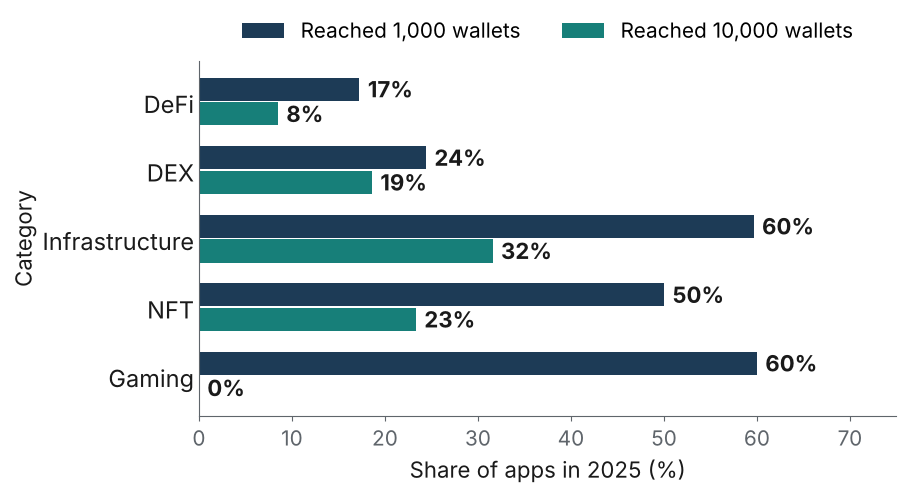

,reached 1k (%),reached 10k (%)
category_group,,
DeFi,17.0,8.0
DEX,24.0,19.0
Infrastructure,60.0,32.0
NFT,50.0,23.0
Gaming,60.0,0.0


In [15]:
by_group = lifecycle[lifecycle["category_group"].isin(G)].groupby("category_group")
reached_1k = by_group["months_to_1k"].apply(lambda s: s.notna().mean() * 100)
reached_10k = by_group["months_to_10k"].apply(lambda s: s.notna().mean() * 100)

fig, ax = plt.subplots(figsize=(W, H))
paired_bars(ax, reached_1k, reached_10k, "Reached 1,000 wallets", "Reached 10,000 wallets",
            "Share of apps in 2025 (%)", 75)
save(fig, "fig8_q34_reach_1k_10k.png")

pd.DataFrame({"reached 1k (%)": reached_1k, "reached 10k (%)": reached_10k}).loc[G].round(0)

In [16]:
first_month = category_month["month"].min().strftime("%Y-%m")
print(f"apps whose busiest month is {first_month}: {lifecycle['peak_month'].astype(str).str.startswith(first_month).mean():.0%}")
print(f"all apps reaching 1,000: {lifecycle['months_to_1k'].notna().mean():.0%}")
print(f"median DeFi peak: {lifecycle.loc[lifecycle['category_group'] == 'DeFi', 'peak_wallets'].median():.0f} wallets")

apps whose busiest month is 2025-01: 34%
all apps reaching 1,000: 27%
median DeFi peak: 7 wallets


## Slide 13. Q6: Retention

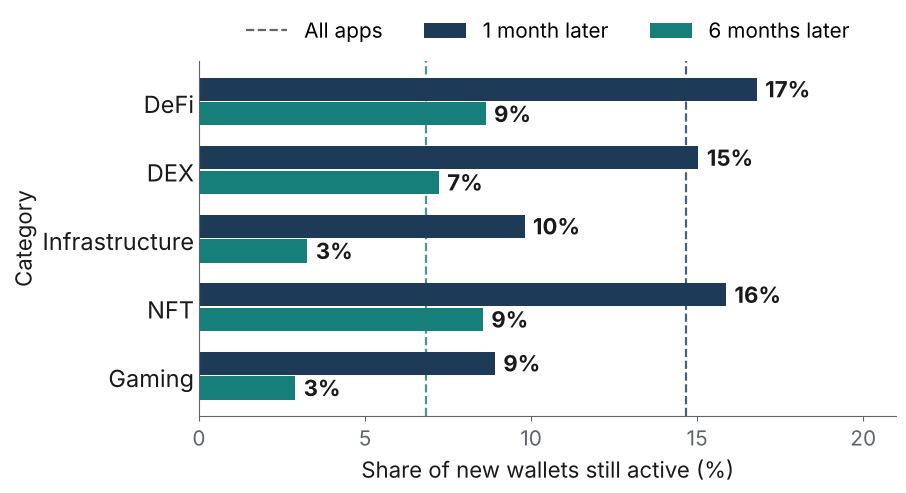

months_since,1,6
category_group,,
DeFi,17.0,9.0
DEX,15.0,7.0
Infrastructure,10.0,3.0
NFT,16.0,9.0
Gaming,9.0,3.0


In [17]:
in_groups = retention[retention["category_group"].isin(G)]
rate = (in_groups[in_groups["months_since"].isin([1, 6])]
        .groupby(["category_group", "months_since"])[["retained", "cohort_size"]].sum())
rate = (rate["retained"] / rate["cohort_size"] * 100).unstack()

fig, ax = plt.subplots(figsize=(W, H))
paired_bars(ax, rate[1], rate[6], "1 month later", "6 months later", "Share of new wallets still active (%)", 21)
ax.set_xticks([0, 5, 10, 15, 20])
overall = retention.groupby("months_since")[["retained", "cohort_size"]].sum()
overall = overall["retained"] / overall["cohort_size"] * 100
for m, c in [(1, NAVY), (6, TEAL)]:
    ax.axvline(overall[m], color=c, linestyle="--", linewidth=1.6, alpha=0.8, zorder=0)
ax.plot([], [], color=GRAY, linestyle="--", linewidth=1.6, label="All apps")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
save(fig, "fig9_q6_retention.png")

rate.loc[G].round(0)

In [18]:
print(f"all apps: {overall[1]:.0f}% after 1 month, {overall[6]:.0f}% after 6 months, {overall[11]:.1f}% after 11 months")

all apps: 15% after 1 month, 7% after 6 months, 4.4% after 11 months


## Slide 14. Q5: Missing early features

In [19]:
launched_2025 = ~lifecycle["launch_month"].astype(str).str.startswith("2025-01")
print(f"already running in Jan 2025: {(~launched_2025).sum()} apps, launched Feb to Dec 2025: {launched_2025.sum()}")
early = ["early_retention", "early_new_wallet_share", "early_tx_per_wallet", "early_gas_per_tx", "early_whale_share"]
(lifecycle[early + ["months_to_1k", "months_to_10k", "decay_ratio"]].isna().mean() * 100).round(0).rename("missing (%)")

already running in Jan 2025: 557 apps, launched Feb to Dec 2025: 65


early_retention           88.0
early_new_wallet_share    86.0
early_tx_per_wallet       86.0
early_gas_per_tx          86.0
early_whale_share         86.0
months_to_1k              73.0
months_to_10k             86.0
decay_ratio               19.0
Name: missing (%), dtype: float64